# Petőfi-GPT – elemzés

Ez a notebook értékeli ki a projekt kísérleteit. Minden modellt **ugyanazokon a teszthalmaz-karaktereken** mér le.

| # | Kísérlet | Kérdés |
|---|---|---|
| 1 | GPT vs. N-gram | Jobb-e a Transformer egy jól simított klasszikus nyelvi modellnél? |
| 2 | GPT vs. Differential Transformer | Segít-e a differenciális attention ezen a méreten? Miben más a figyelme? |
| 3 | Ablationök | Mennyit számít a residual kapcsolat és az aktiváció (GELU vs. ReLU)? |
| 4 | Temperature és top-k | Hogyan változik a generált szöveg minősége és változatossága? |

**Módszertan röviden**
- A hiperparamétereket (a dropoutot és az N-gram rendjét) **csak a val halmazon** választjuk ki (1. rész).
- A **teszthalmazt csak a kiválasztott modellekre** használjuk, egyszer (2. rész).
- A bizonytalanságot **versenkénti bootstrap**-pel becsüljük: a 117 test-verset sorsoljuk újra visszatevéssel, 2000-szer. Egy versen belül a karakterek nem függetlenek egymástól, ezért a vers a mintavétel egysége.

**Futtatás:** a repó gyökeréből, a `petofi-gpt` kernellel. Kell hozzá a `data/` (`python prepare_data.py`) és a `checkpoints/` mappában mind a 8 modell (`python download.py` letölti őket a Release-ből). CPU-n kb. 10–15 perc.

In [1]:
import json, math, re, sys
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from scipy import stats

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from generate import load_model                 # rebuilds a model from a checkpoint
from ngram_baseline import NGramModel

DATA, CKPT, RESULTS = ROOT / "data", ROOT / "checkpoints", ROOT / "results"
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)
torch.set_grad_enabled(False)                   # evaluation only: no gradients anywhere
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

meta = json.loads((DATA / "meta.json").read_text(encoding="utf-8"))
vocab = meta["vocab"]
stoi = {ch: i for i, ch in enumerate(vocab)}
train_text, val_text, test_text = ((DATA / f"{s}.txt").read_text(encoding="utf-8") for s in ("train", "val", "test"))
print(f"device: {DEVICE} | test: {len(test_text):,} karakter | szótár: {len(vocab)}")

device: cpu | test: 96,844 karakter | szótár: 97


---
## 1. Modellválasztás a validációs halmazon

Minden checkpoint tartalmazza a saját tanítási görbéjét (`history`) és a legjobb val loss-t. Itt a tanulás eredményeit nézzük meg, és **a val alapján** kiválasztjuk a végleges GPT-t és a végleges DIFF-et. A teszthalmazt ehhez nem használjuk.

In [2]:
RUNS = {   # checkpoint name -> label
    "cpu":                "GPT, CPU-preset (0,8M)",
    "colab":              "GPT, dropout 0.2",
    "colab_drop03":       "GPT, dropout 0.3",
    "colab_drop04":       "GPT, dropout 0.4",
    "colab_drop03_relu":  "GPT, ReLU (dropout 0.3)",
    "colab_drop03_nores": "GPT, residual nélkül (dropout 0.3)",
    "colab_drop02_diff":  "DIFF, dropout 0.2",
    "colab_drop03_diff":  "DIFF, dropout 0.3",
}
info = {}
for name, label in RUNS.items():
    path = CKPT / f"{name}.pt"
    if not path.exists():
        print(f"hiányzik: {path.name}")
        continue
    ck = torch.load(path, map_location="cpu", weights_only=True)
    info[name] = {"label": label, "best_val": ck["best_val_loss"], "iter": ck["iter"],
                  "config": ck["config"], "history": ck["history"],
                  "params": sum(t.numel() for t in ck["model"].values())}

print(f"{'checkpoint':20} {'paraméter':>11} {'dropout':>7} {'legjobb val':>11} {'ppl':>6} {'lépés':>6}")
for name, d in info.items():
    print(f"{name:20} {d['params']:11,d} {d['config']['dropout']:7.1f} {d['best_val']:11.4f} "
          f"{math.exp(d['best_val']):6.2f} {d['iter']:6d}")

checkpoint             paraméter dropout legjobb val    ppl  lépés
cpu                      834,560     0.1      1.6992   5.47   3000
colab                 10,820,352     0.2      1.5972   4.94   1600
colab_drop03          10,820,352     0.3      1.5751   4.83   2400
colab_drop04          10,820,352     0.4      1.5894   4.90   4000
colab_drop03_relu     10,820,352     0.3      1.5654   4.78   2600
colab_drop03_nores    10,820,352     0.3      3.4088  30.23   1800
colab_drop02_diff     10,822,656     0.2      1.6168   5.04   2400
colab_drop03_diff     10,822,656     0.3      1.6416   5.16   3400


végleges GPT (val alapján):  colab_drop03 - GPT, dropout 0.3
végleges DIFF (val alapján): colab_drop02_diff - DIFF, dropout 0.2


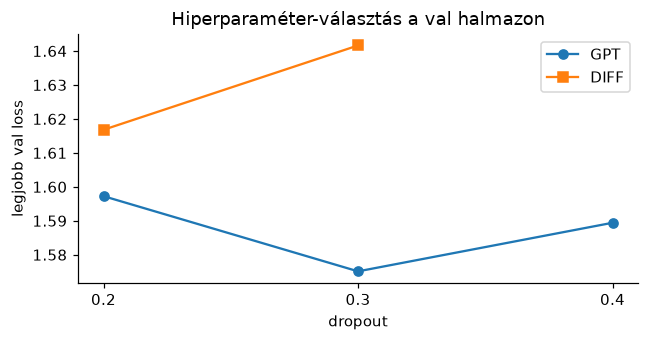

In [3]:
def best_of(names):
    present = [n for n in names if n in info]
    return min(present, key=lambda n: info[n]["best_val"])

GPT_FINAL = best_of(["colab", "colab_drop03", "colab_drop04"])     # hyperparameter: dropout
DIFF_FINAL = best_of(["colab_drop02_diff", "colab_drop03_diff"])
print("végleges GPT (val alapján): ", GPT_FINAL, "-", info[GPT_FINAL]["label"])
print("végleges DIFF (val alapján):", DIFF_FINAL, "-", info[DIFF_FINAL]["label"])

fig, ax = plt.subplots(figsize=(6, 3.2))
for names, lab, mk in [(["colab", "colab_drop03", "colab_drop04"], "GPT", "o-"),
                       (["colab_drop02_diff", "colab_drop03_diff"], "DIFF", "s-")]:
    present = [n for n in names if n in info]
    ax.plot([info[n]["config"]["dropout"] for n in present], [info[n]["best_val"] for n in present], mk, label=lab)
ax.set_xticks([0.2, 0.3, 0.4])
ax.set_xlabel("dropout"); ax.set_ylabel("legjobb val loss"); ax.legend()
ax.set_title("Hiperparaméter-választás a val halmazon")
plt.tight_layout(); plt.savefig(FIG / "dropout_selection.png", dpi=150); plt.show()

**A dropout választása:** túl kevés regularizációnál a modell túltanul (a val loss korán megfordul), túl soknál lassan tanul. A végleges modellek a görbék minimumánál vannak.

### Tanulási görbék

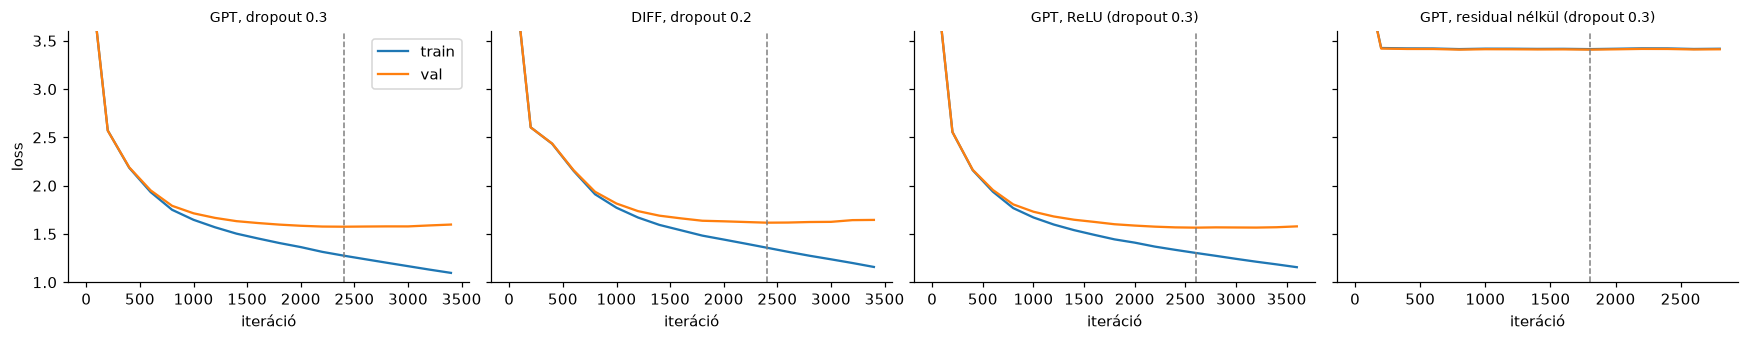

In [4]:
show = [GPT_FINAL, DIFF_FINAL, "colab_drop03_relu", "colab_drop03_nores"]
show = [n for n in show if n in info]
fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 3.2), sharey=True)
for ax, name in zip(np.atleast_1d(axes), show):
    h = info[name]["history"]
    it = [p["iter"] for p in h]
    ax.plot(it, [p["train"] for p in h], label="train")
    ax.plot(it, [p["val"] for p in h], label="val")
    ax.axvline(info[name]["iter"], color="gray", ls="--", lw=1)
    ax.set_title(info[name]["label"], fontsize=9); ax.set_xlabel("iteráció")
np.atleast_1d(axes)[0].set_ylabel("loss"); np.atleast_1d(axes)[0].legend()
np.atleast_1d(axes)[0].set_ylim(1.0, 3.6)
plt.tight_layout(); plt.savefig(FIG / "learning_curves.png", dpi=150); plt.show()

A szaggatott vonal az early stopping által megtartott lépés. Ahol utána a train loss tovább csökken, a val loss pedig nő, ott a modell túltanulna. A residual nélküli modell nem jut túl a betűgyakoriság (unigram) szintjén.

---
## 2. Kiértékelés a teszthalmazon

### 2.1 Karakterenkénti loss minden modellre

Minden modell a teszt **minden karakterére** (az elsőt kivéve) ad egy $-\ln p(\text{helyes karakter})$ értéket, így a modellek pozícióról pozícióra összevethetők.

- **GPT/DIFF:** csúszó ablak (`block_size` hossz, fél ablaknyi lépés). Minden karaktert csak egyszer pontozunk, és a modell mindig legalább fél ablaknyi előzményt lát.
- **N-gram:** az előző $n-1$ karakter; az *n*-t a val halmazon választjuk.

In [5]:
test_ids = torch.tensor([stoi[c] for c in test_text], dtype=torch.long)
N = len(test_ids)

def gpt_token_losses(model, ids, batch_size=16):
    # -ln p(ids[j] | previous characters) for j = 1..N-1, with a sliding window
    T = model.config.block_size
    stride = T // 2
    n = len(ids)
    starts = list(range(0, n - T, stride))
    if starts[-1] + T < n - 1:
        starts.append(n - 1 - T)
    jobs, done = [], 0                      # done = last target position already scored
    for s in starts:                        # window s predicts target positions s+1 .. s+T
        jobs.append((s, max(s + 1, done + 1) - (s + 1)))
        done = s + T
    out = torch.full((n - 1,), float("nan"))
    device = next(model.parameters()).device
    for b in range(0, len(jobs), batch_size):
        chunk = jobs[b:b + batch_size]
        x = torch.stack([ids[s:s + T] for s, _ in chunk]).to(device)
        y = torch.stack([ids[s + 1:s + T + 1] for s, _ in chunk]).to(device)
        logits, _ = model(x)
        nll = F.cross_entropy(logits.transpose(1, 2), y, reduction="none").cpu()   # (b, T)
        for (s, off), row in zip(chunk, nll):
            out[s + off:s + T] = row[off:]  # target position j is stored at index j - 1
    assert not torch.isnan(out).any()
    return out.numpy().astype(np.float64)

losses = {}
for name in [GPT_FINAL, DIFF_FINAL, "colab_drop03_relu", "colab_drop03_nores", "cpu"]:
    if name in info and name not in losses:
        model, _ = load_model(CKPT / f"{name}.pt", DEVICE)
        losses[name] = gpt_token_losses(model, test_ids)
        print(f"{name:20} test loss {losses[name].mean():.4f}")

colab_drop03         test loss 1.5560
colab_drop02_diff    test loss 1.6061
colab_drop03_relu    test loss 1.5458
colab_drop03_nores   test loss 3.4226
cpu                  test loss 1.6811


In [6]:
ngram_json = RESULTS / "ngram_baseline.json"
if ngram_json.exists():
    BEST_N = json.loads(ngram_json.read_text(encoding="utf-8"))["best_n"]
else:                                        # choose n on VAL if the json is missing
    ng = NGramModel(vocab, 8).fit(train_text)
    BEST_N = min(range(1, 9), key=lambda n: ng.loss(val_text, n))
ngram = NGramModel(vocab, BEST_N).fit(train_text)
NGRAM = f"{BEST_N}-gram"
losses[NGRAM] = np.array(ngram.token_losses(test_text, BEST_N))
info[NGRAM] = {"label": f"{BEST_N}-gram (Witten–Bell)"}
print(f"{NGRAM}: test loss {losses[NGRAM].mean():.4f}  (n a val alapján)")
assert all(len(v) == N - 1 for v in losses.values())

5-gram: test loss 1.7722  (n a val alapján)


### 2.2 Eredménytábla bootstrap konfidencia-intervallummal

A test-verseket (117 db) **2000-szer újrasorsoljuk visszatevéssel**, és mindegyik mintán kiszámoljuk a loss-t. A 2,5%-os és a 97,5%-os percentilis adja a **95%-os konfidencia-intervallumot** (CI). Minden modell ugyanazokat a sorsolásokat kapja, így a különbségek is párosan becsülhetők.

modell                                 test loss             95% CI    ppl  bit/kar.
GPT, ReLU (dropout 0.3)                   1.5458  [1.5130, 1.5773]   4.69     2.230
GPT, dropout 0.3                          1.5560  [1.5234, 1.5876]   4.74     2.245
DIFF, dropout 0.2                         1.6061  [1.5765, 1.6355]   4.98     2.317
GPT, CPU-preset (0,8M)                    1.6811  [1.6551, 1.7073]   5.37     2.425
5-gram (Witten–Bell)                      1.7722  [1.7435, 1.8026]   5.88     2.557
GPT, residual nélkül (dropout 0.3)        3.4226  [3.4105, 3.4357]  30.65     4.938


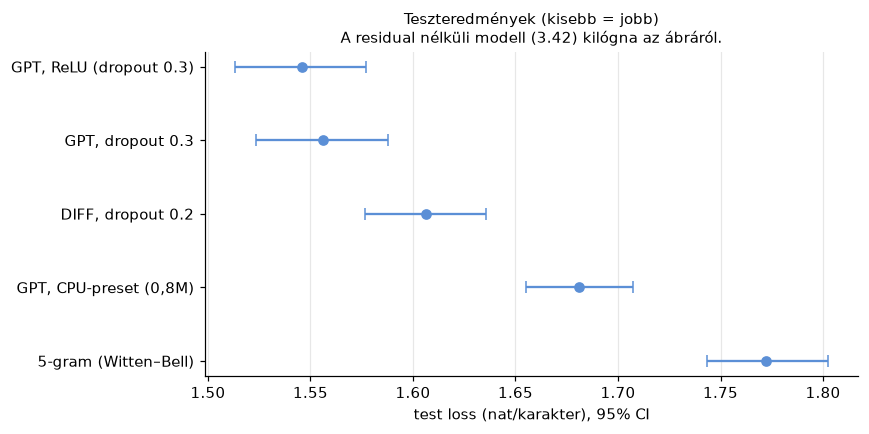

In [7]:
test_poems = [p for p in json.loads((DATA / "poems.json").read_text(encoding="utf-8")) if p["split"] == "test"]
starts = np.cumsum([0] + [len(p["text"]) + 3 for p in test_poems[:-1]])   # 3 = len("\n\n\n")
poem_of = np.searchsorted(starts, np.arange(1, N), side="right") - 1        # poem of target j
P = len(test_poems)
counts = np.bincount(poem_of, minlength=P)

rng = np.random.default_rng(0)
BOOT = rng.integers(0, P, size=(2000, P))                                   # shared resamples

def poem_sums(x):
    return np.bincount(poem_of, weights=x, minlength=P)

def boot_mean(x):
    s = poem_sums(x)
    samples = s[BOOT].sum(1) / counts[BOOT].sum(1)
    return float(x.mean()), float(np.percentile(samples, 2.5)), float(np.percentile(samples, 97.5))

results = {}
order = sorted(losses, key=lambda n: losses[n].mean())
print(f"{'modell':38} {'test loss':>9}  {'95% CI':>17}  {'ppl':>5}  {'bit/kar.':>8}")
for name in order:
    m, lo, hi = boot_mean(losses[name])
    results[name] = {"label": info[name]["label"], "loss": m, "ci": [lo, hi], "ppl": math.exp(m),
                     "ppl_ci": [math.exp(lo), math.exp(hi)], "bits_per_char": m / math.log(2)}
    print(f"{info[name]['label']:38} {m:9.4f}  [{lo:.4f}, {hi:.4f}]  {math.exp(m):5.2f}  {m / math.log(2):8.3f}")

plot_names = [n for n in order if n != "colab_drop03_nores"]          # it would squash the axis
ys = np.arange(len(plot_names))[::-1]
fig, ax = plt.subplots(figsize=(8, 0.55 * len(plot_names) + 1.3))
ax.errorbar([results[n]["loss"] for n in plot_names], ys, fmt="o", color="#5b8fd6", capsize=4,
            xerr=np.array([[results[n]["loss"] - results[n]["ci"][0], results[n]["ci"][1] - results[n]["loss"]]
                           for n in plot_names]).T)
ax.set_yticks(ys, [results[n]["label"] for n in plot_names]); ax.grid(axis="x", alpha=0.3)
ax.set_xlabel("test loss (nat/karakter), 95% CI")
title = "Teszteredmények (kisebb = jobb)"
if "colab_drop03_nores" in results:
    title += f"\nA residual nélküli modell ({results['colab_drop03_nores']['loss']:.2f}) kilógna az ábráról."
ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "test_results.png", dpi=150); plt.show()

### 2.3 Páros összehasonlítások

A különbség **„A − B”**: negatív érték esetén az A modell a jobb. Ha a különbség 95%-os CI-je **nem tartalmazza a 0-t**, a különbség a teszthalmaz versein statisztikailag megbízható.

Kiegészítésként a versenkénti átlagos loss-okon **Wilcoxon előjeles rangpróbát** is végzünk (páros, nemparaméteres próba).

**Fontos korlát:** a CI azt méri, mennyire bizonytalan az eredmény **a test-versek kiválasztása** miatt. Azt nem méri, hogy egy másik seeddel tanított modell mennyire térne el. Beállításonként egyetlen tanítás futott, ezért a nagyon kicsi (kb. 0,01-es) különbségekből nem vonunk le általános következtetést.

In [8]:
def compare(a, b):
    d = losses[a] - losses[b]
    m, lo, hi = boot_mean(d)
    per_poem = poem_sums(losses[a]) / counts - poem_sums(losses[b]) / counts
    p = float(stats.wilcoxon(per_poem).pvalue)
    better = sum(per_poem < 0)
    return {"a": a, "b": b, "diff": m, "ci": [lo, hi], "wilcoxon_p": p, "a_better_poems": int(better)}

pairs = [(GPT_FINAL, NGRAM, "1. GPT vs. N-gram"),
         (DIFF_FINAL, GPT_FINAL, "2. DIFF vs. GPT"),
         ("colab_drop03_relu", GPT_FINAL, "3a. ReLU vs. GELU"),
         ("colab_drop03_nores", GPT_FINAL, "3b. residual nélkül vs. GPT"),
         (GPT_FINAL, "cpu", "nagy vs. kis GPT")]
comparisons = {}
for a, b, title in pairs:
    if a in losses and b in losses:
        c = compare(a, b)
        comparisons[title] = c
        sig = "megbízható" if (c["ci"][0] > 0 or c["ci"][1] < 0) else "NEM megbízható (a CI tartalmazza a 0-t)"
        print(f"{title:30} {c['diff']:+.4f}  95% CI [{c['ci'][0]:+.4f}, {c['ci'][1]:+.4f}]  "
              f"Wilcoxon p={c['wilcoxon_p']:.1e}  az első jobb {c['a_better_poems']}/{P} versben  -> {sig}")

1. GPT vs. N-gram              -0.2163  95% CI [-0.2277, -0.2049]  Wilcoxon p=6.3e-21  az első jobb 116/117 versben  -> megbízható
2. DIFF vs. GPT                +0.0501  95% CI [+0.0426, +0.0575]  Wilcoxon p=2.0e-20  az első jobb 6/117 versben  -> megbízható
3a. ReLU vs. GELU              -0.0102  95% CI [-0.0147, -0.0059]  Wilcoxon p=1.2e-04  az első jobb 77/117 versben  -> megbízható
3b. residual nélkül vs. GPT    +1.8666  95% CI [+1.8393, +1.8949]  Wilcoxon p=6.1e-21  az első jobb 0/117 versben  -> megbízható
nagy vs. kis GPT               -0.1252  95% CI [-0.1360, -0.1139]  Wilcoxon p=6.1e-21  az első jobb 117/117 versben  -> megbízható


### 2.4 Hol nyer a GPT az N-gramon? Loss a verssoron belüli pozíció szerint

Az N-gram csak az előző néhány karaktert látja, a GPT 256-ot. Ha a különbség a sor elején nagyobb, akkor a GPT a sorok közötti összefüggéseket (versszerkezet, ismétlődő sorkezdetek) is kihasználja.

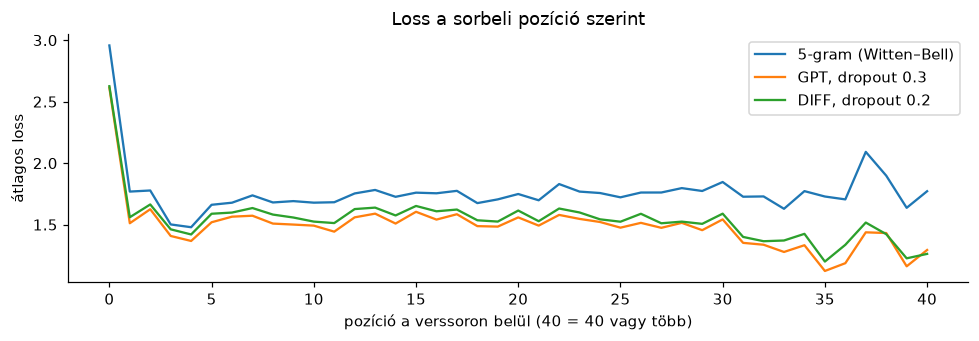

5-gram (Witten–Bell)           sorkezdő karakter: 2.957 | többi: 1.717
GPT, dropout 0.3               sorkezdő karakter: 2.614 | többi: 1.507


In [9]:
col = np.empty(N - 1, dtype=int)                 # position of target j within its line
pos = 0
for j in range(1, N):
    col[j - 1] = pos
    pos = 0 if test_text[j] == "\n" else pos + 1
bins = np.minimum(col, 40)

fig, ax = plt.subplots(figsize=(9, 3.2))
for name in [NGRAM, GPT_FINAL, DIFF_FINAL]:
    if name in losses:
        mean_by_col = np.bincount(bins, weights=losses[name]) / np.bincount(bins)
        ax.plot(range(41), mean_by_col, label=info[name]["label"])
ax.set_xlabel("pozíció a verssoron belül (40 = 40 vagy több)"); ax.set_ylabel("átlagos loss")
ax.legend(); ax.set_title("Loss a sorbeli pozíció szerint")
plt.tight_layout(); plt.savefig(FIG / "loss_by_line_position.png", dpi=150); plt.show()

first = col == 0
for name in [NGRAM, GPT_FINAL]:
    print(f"{info[name]['label']:30} sorkezdő karakter: {losses[name][first].mean():.3f} | többi: {losses[name][~first].mean():.3f}")

---
## 3. A figyelem összehasonlítása: GPT vs. DIFF

A Differential Transformer cikk állítása, hogy a két softmax-térkép különbsége **kioltja a lényegtelen pozíciókra jutó „zaj-figyelmet”**, így a figyelem fókuszáltabb lesz. Ezt két módon nézzük meg:
1. **hőtérképek** egy test-versszakon;
2. **számszerűen**, sok test-ablakon: az attention-sorok normalizált **entrópiája** (0 = egyetlen pozícióra figyel, 1 = egyenletesen mindenre) és a **top-5 tömeg** (a figyelem hány százaléka jut az 5 legerősebb pozícióra).

A DIFF-térkép értékei negatívak is lehetnek. Az összevetéshez ezért soronként az abszolút értékeket normáljuk 1-re ($|a| / \sum |a|$); a GPT-nél ez maga a softmax.

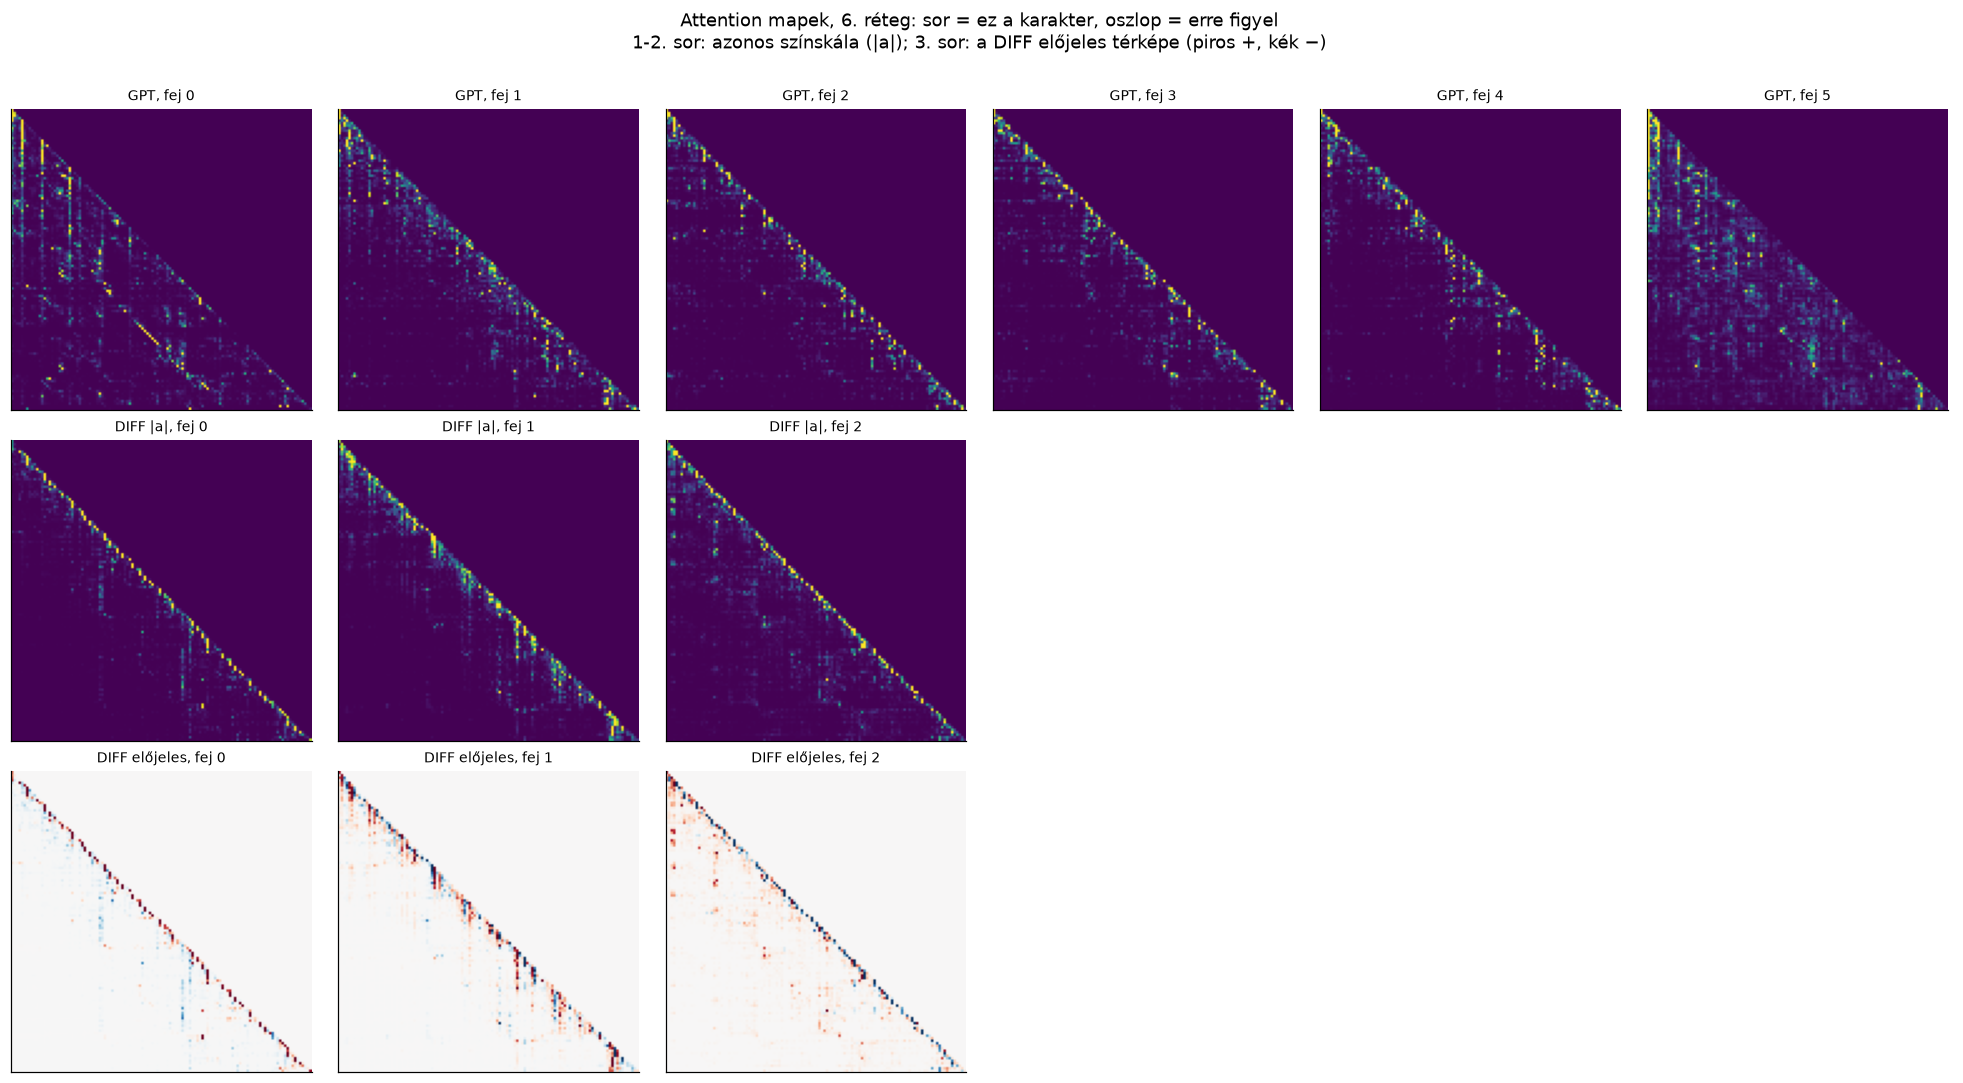

'Mely emésztő hatalommal rám szakadt,\nKeservesen megsiratni van okom –\nE két tavaszt megsiratni nem fogom.\n\nHű bajtárs, e'


In [10]:
gpt_model, _ = load_model(CKPT / f"{GPT_FINAL}.pt", DEVICE)
diff_model, _ = load_model(CKPT / f"{DIFF_FINAL}.pt", DEVICE)

def attention_maps(model, ids):
    model.set_store_attention(True)
    model(ids.unsqueeze(0).to(DEVICE))
    maps = [m[0].cpu() for m in model.attention_maps()]       # per layer: (heads, T, T)
    model.set_store_attention(False)
    return maps

poem = next(p for p in test_poems if len(p["text"]) > 600)
start = poem["text"].index("\n", 200) + 1                      # a line start inside the poem
excerpt = poem["text"][start:start + 120]
ids = torch.tensor([stoi[c] for c in excerpt])
g_maps, d_maps = attention_maps(gpt_model, ids), attention_maps(diff_model, ids)
LAYER = len(g_maps) - 1                                         # last layer
labels = ["↵" if c == "\n" else ("␣" if c == " " else c) for c in excerpt]

ncols = max(len(g_maps[LAYER]), len(d_maps[LAYER]))
rows = [("GPT", g_maps[LAYER], False), ("DIFF |a|", d_maps[LAYER], False), ("DIFF előjeles", d_maps[LAYER], True)]
fig, axes = plt.subplots(3, ncols, figsize=(3.0 * ncols, 10))
for r, (name, maps, signed) in enumerate(rows):
    for h in range(ncols):
        ax = axes[r, h]
        ax.set_xticks([]); ax.set_yticks([])
        if h >= len(maps):
            ax.axis("off")
            continue
        a = maps[h] if signed else maps[h].abs()
        v = torch.quantile(a.abs()[a != 0], 0.99).item()        # clip the few very large values
        if signed:
            ax.imshow(a, cmap="RdBu_r", vmin=-v, vmax=v)
        else:
            ax.imshow(a, cmap="viridis", vmin=0, vmax=v)
        ax.set_title(f"{name}, fej {h}", fontsize=9)
fig.suptitle(f"Attention mapek, {LAYER + 1}. réteg: sor = ez a karakter, oszlop = erre figyel\n"
             "1-2. sor: azonos színskála (|a|); 3. sor: a DIFF előjeles térképe (piros +, kék −)")
plt.tight_layout(h_pad=2, rect=(0, 0, 1, 0.965))                 # leave room for the 2-line title
plt.savefig(FIG / "attention_maps.png", dpi=150); plt.show()
print(repr(excerpt))

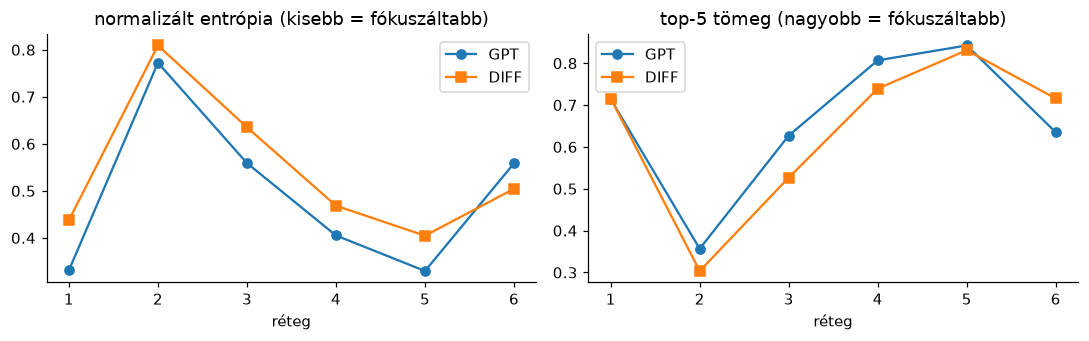

DIFF lambda rétegenként: [0.111, 0.191, 0.298, 0.36, 0.663, 0.637]
átlag entrópia  GPT 0.493 | DIFF 0.543
átlag top-5     GPT 0.664 | DIFF 0.639


In [11]:
def focus_stats(model, n_windows=24, min_row=32):
    # mean normalized entropy and top-5 mass of attention rows, per layer
    T = model.config.block_size
    gen = np.random.default_rng(1)
    ent = np.zeros(len(model.blocks)); top5 = np.zeros(len(model.blocks)); n = 0
    for s in gen.integers(0, N - T, n_windows):
        maps = attention_maps(model, test_ids[s:s + T])
        for l, m in enumerate(maps):                             # m: (heads, T, T)
            p = m.abs()[:, min_row:, :]
            p = p / p.sum(-1, keepdim=True)
            t = torch.arange(min_row, T).float() + 1              # number of visible positions
            e = -(p * torch.log(p.clamp_min(1e-12))).sum(-1) / torch.log(t)
            ent[l] += e.mean().item()
            top5[l] += torch.topk(p, 5, dim=-1).values.sum(-1).mean().item()
        n += 1
    return ent / n, top5 / n

g_ent, g_top = focus_stats(gpt_model)
d_ent, d_top = focus_stats(diff_model)
layers = np.arange(1, len(g_ent) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(layers, g_ent, "o-", label="GPT"); axes[0].plot(layers, d_ent, "s-", label="DIFF")
axes[0].set_title("normalizált entrópia (kisebb = fókuszáltabb)")
axes[1].plot(layers, g_top, "o-", label="GPT"); axes[1].plot(layers, d_top, "s-", label="DIFF")
axes[1].set_title("top-5 tömeg (nagyobb = fókuszáltabb)")
for ax in axes: ax.set_xlabel("réteg"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "attention_focus.png", dpi=150); plt.show()

lambdas = [blk.attn.lambda_value().item() for blk in diff_model.blocks]
print("DIFF lambda rétegenként:", [round(x, 3) for x in lambdas])
print(f"átlag entrópia  GPT {g_ent.mean():.3f} | DIFF {d_ent.mean():.3f}")
print(f"átlag top-5     GPT {g_top.mean():.3f} | DIFF {d_top.mean():.3f}")

---
## 4. Temperature és top-k a generálásban

A végleges GPT-vel minden beállításhoz 4 × 400 karaktert generálunk, fix seeddel. Két egyszerű mérőszámot számolunk:
- **valódi szavak aránya:** a generált szavak hány százaléka fordul elő a tanítószövegben (helyesség);
- **különböző szavak aránya:** egyedi szavak / összes szó (változatosság; alacsony érték = ismétlődés).

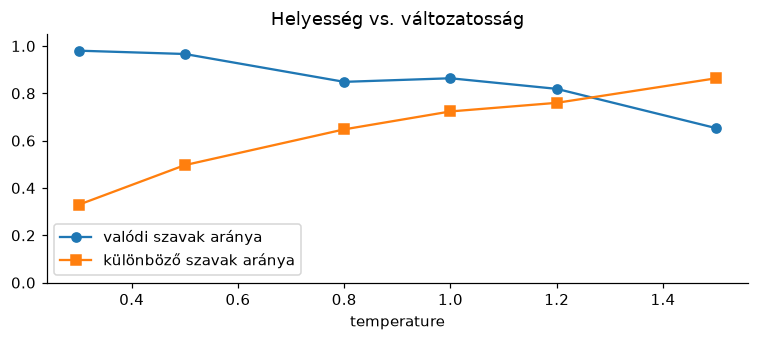

top-k (temperature 1.0):
  top-k 1    : valódi szavak 100.0%, különböző szavak 4.8%
  top-k 5    : valódi szavak 90.7%, különböző szavak 60.5%
  top-k 20   : valódi szavak 83.8%, különböző szavak 70.3%
  top-k nincs: valódi szavak 86.4%, különböző szavak 72.3%


In [12]:
train_words = set(re.findall(r"[^\W\d_]+", train_text.lower()))

def sample_texts(model, temperature, top_k, n=4, length=400, seed=42):
    torch.manual_seed(seed)
    start = torch.full((n, 1), stoi["\n"], dtype=torch.long, device=DEVICE)
    out = model.generate(start, length, temperature=temperature, top_k=top_k)
    return ["".join(vocab[i] for i in row[1:].tolist()) for row in out]

def text_metrics(texts):
    words = [w for t in texts for w in re.findall(r"[^\W\d_]+", t.lower())]
    return {"valid": sum(w in train_words for w in words) / len(words), "distinct": len(set(words)) / len(words)}

temps = [0.3, 0.5, 0.8, 1.0, 1.2, 1.5]
temp_res = {t: text_metrics(sample_texts(gpt_model, t, None)) for t in temps}
topks = [1, 5, 20, None]
topk_res = {k: text_metrics(sample_texts(gpt_model, 1.0, k)) for k in topks}

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(temps, [temp_res[t]["valid"] for t in temps], "o-", label="valódi szavak aránya")
ax.plot(temps, [temp_res[t]["distinct"] for t in temps], "s-", label="különböző szavak aránya")
ax.set_xlabel("temperature"); ax.set_ylim(0, 1.05); ax.legend(); ax.set_title("Helyesség vs. változatosság")
plt.tight_layout(); plt.savefig(FIG / "temperature.png", dpi=150); plt.show()

print("top-k (temperature 1.0):")
for k in topks:
    print(f"  top-k {str(k or 'nincs'):5}: valódi szavak {topk_res[k]['valid']:.1%}, különböző szavak {topk_res[k]['distinct']:.1%}")

In [13]:
for t in (0.3, 0.8, 1.5):
    print(f"=== temperature {t} ===\n{sample_texts(gpt_model, t, None, n=1, length=300)[0]}\n")
print(f"=== top-k 1 (mindig a legvalószínűbb) ===\n{sample_texts(gpt_model, 1.0, 1, n=1, length=300)[0]}")

=== temperature 0.3 ===

Minden a világ a világ,
Minden ember szemedben a világ,
Mint a kis fiú, minden világ!



A mint a magyar nép

Mi a magyar nép, mi a magyar nép!
Nem a magyar nép, ha meghalni,
Magyar nép, meghalni a magyar nép!


A magyar nép

Magyar nép

Magyar nép e kis fiú,
Mint a magyar nép az ég,
A mely szép vi

=== temperature 0.8 ===
És ő fogadja volt a királyt.

Mit beszélek: »Homlokány a hirtelen élet!«
Mit beszéltem, mint a ti jó szép alak,
Ki beszéltém alutt, hogy ne megyek,
A ki nem maradjon meg, mint a hegyre?

Mért nem lesz senki sem tehetném,
A mért kedves örömben, mert az ember;
Magyar hazám! tudja mi a második szivembe

=== temperature 1.5 ===
Értő fogadást dörfelhőket,
Pillangott szavának,
Útazólag leveledtek őket,
…
Miket. ‚Im, légy fits, mit alél jár?«

SZóla Zolda, subához az utczán,
És János cziklója fű
Alszik kóapu czirtája, se…
Rabollaga börtönt emeltünket,
És kéteket alából, az
Unokáknál dicsőség,
Agg isten magyar,
Kövéből, hanem 

=== top-k 1 (mindig a 

---
## 5. Összefoglalás és az eredmények mentése

Az alábbi cella a fontosabb számokat a `results/` mappába menti (`test_results.json`), az ábrák a `results/figures/` mappába kerültek. Ezekre hivatkozik a README.

In [14]:
summary = {
    "selection": {"gpt_final": GPT_FINAL, "diff_final": DIFF_FINAL, "ngram_n": BEST_N,
                  "val": {n: info[n]["best_val"] for n in info if "best_val" in info[n]}},
    "test": results,
    "comparisons": comparisons,
    "attention": {"gpt_entropy": g_ent.tolist(), "diff_entropy": d_ent.tolist(),
                  "gpt_top5": g_top.tolist(), "diff_top5": d_top.tolist(), "diff_lambda": lambdas},
    "sampling": {"temperature": {str(t): v for t, v in temp_res.items()},
                 "top_k_at_T1": {str(k): v for k, v in topk_res.items()}},
}
(RESULTS / "test_results.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8", newline="\n")

g, ng, d = results[GPT_FINAL], results[NGRAM], results[DIFF_FINAL]
print(f"GPT  test ppl {g['ppl']:.2f}  [{g['ppl_ci'][0]:.2f}, {g['ppl_ci'][1]:.2f}]")
print(f"{NGRAM} test ppl {ng['ppl']:.2f}  [{ng['ppl_ci'][0]:.2f}, {ng['ppl_ci'][1]:.2f}]")
print(f"DIFF test ppl {d['ppl']:.2f}  [{d['ppl_ci'][0]:.2f}, {d['ppl_ci'][1]:.2f}]")
print("mentve: results/test_results.json | ábrák:", sorted(p.name for p in FIG.glob("*.png")))

GPT  test ppl 4.74  [4.59, 4.89]
5-gram test ppl 5.88  [5.72, 6.07]
DIFF test ppl 4.98  [4.84, 5.13]
mentve: results/test_results.json | ábrák: ['attention_focus.png', 'attention_maps.png', 'dropout_selection.png', 'learning_curves.png', 'loss_by_line_position.png', 'temperature.png', 'test_results.png']


---
## 6. Következtetések

**1. GPT vs. N-gram.** A végleges GPT (10,8M paraméter, dropout 0,3) test perplexityje **4,74** [4,59; 4,89], a val alapján választott 5-gramé **5,88** [5,72; 6,07]. A különbség −0,216 nat/karakter [−0,228; −0,205], és **a 117 test-versből 116-ban** a GPT a jobb. A loss-görbe a verssoron belül megmutatja, hol nyer: a **sorkezdő karaktereknél** (2,61 vs. 2,96) és a **hosszú sorok végén**. Ezekhez a jóslatokhoz az előző sor(ok) ismerete kell (versszerkezet, sorhossz, rím), amit az 5 karakteres kontextus nem lát.

**2. GPT vs. Differential Transformer.** A DIFF (a saját legjobb dropoutjával, 0,2-vel) test perplexityje **4,98** [4,84; 5,13], vagyis **rosszabb** a GPT-nél: +0,050 nat/karakter [+0,043; +0,058], és a GPT 111/117 versben jobb. A figyelem sem lett fókuszáltabb: az átlagos normalizált entrópia GPT-nél 0,493, DIFF-nél 0,543, a top-5 tömeg 0,664, illetve 0,639. A tanult λ a mélységgel nő (0,11 → 0,66), a cikkben javasolt kezdőérték-ütemezéshez hasonlóan.
*Értelmezés:* a cikk az előnyt milliárdos paraméterszámú modelleken, hosszú kontextusban (sok lényegtelen tokennel) mutatta ki. Nálunk kicsi a modell, 256 karakteres a kontextus, és a versben kevés a kioltandó „zaj”. A DIFF ráadásul fele annyi (3) fejjel dolgozik, ami kis modellnél hátrány lehet. Ezen a méreten tehát **nem igazolódott** a DIFF előnye.

**3. Ablationök.**
- **Residual kapcsolat nélkül** a modell megreked a betűgyakoriság szintjén (test loss 3,42 vs. unigram ≈ 3,40): +1,87 nat/karakter. A residual kapcsolat nélkülözhetetlen a mély Transformer tanításához.
- **ReLU vs. GELU:** a ReLU kicsit jobb lett (−0,010 nat/karakter, 77/117 versben). A különbség a test-versek szerint kimutatható, de nagyon kicsi (kb. 0,65%), és beállításonként egyetlen tanítás futott. Ezért a két aktivációt **gyakorlatilag egyenértékűnek** tekintjük.
- **Modellméret:** a 10,8M paraméteres modell 0,125 nat/karakterrel jobb a 0,8M-esnél, mind a 117 versben.

**4. Temperature és top-k.** A temperature növelésével a változatosság nő (különböző szavak aránya 0,3-nál ~33% → 1,5-nél ~86%), a helyesség csökken (valódi szavak aránya ~98% → ~65%). Alacsony temperature-nél és top-k = 1-nél a modell ismétlésbe ragad („magyar nép, magyar nép…”). Jó egyensúly kb. 0,8–1,0 között, illetve top-k 5–20-szal van.

**Korlátok:** beállításonként egyetlen seed; a val loss fix batch-eken mért becslés; karakter-szintű modell régi helyesírással; a teszthalmazban csak lírai versek vannak (az elbeszélő költemények a trainben vannak).